In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LONDON = "../data/raw/london"
BLOCKS = os.path.join(LONDON, "hhblock_dataset", "hhblock_dataset")

hh = pd.read_csv(os.path.join(LONDON, "informations_households.csv"))
sample_blocks = [f"block_{i}" for i in range(10)]
hh_s = hh[hh["file"].isin(sample_blocks)].copy()
print(hh_s["stdorToU"].value_counts())

frames = [pd.read_csv(os.path.join(BLOCKS, f"{b}.csv"), parse_dates=["day"]) for b in sample_blocks]
raw = pd.concat(frames, ignore_index=True)
print("all years:", raw.shape)

raw = raw[(raw["day"] >= "2013-01-01") & (raw["day"] <= "2013-12-31")].copy()
print("2013 only:", raw.shape, "| households:", raw["LCLid"].nunique())

stdorToU
Std    379
ToU    121
Name: count, dtype: int64
all years: (300147, 50)
2013 only: (171677, 50) | households: 492


In [2]:
hh_cols = [f"hh_{i}" for i in range(48)]

print("missing readings:", int(raw[hh_cols].isna().sum().sum()))
print("negative readings:", int((raw[hh_cols] < 0).sum().sum()))
print("duplicate household-days:", int(raw.duplicated(["LCLid", "day"]).sum()))
print("rows with all 48 slots missing:", int(raw[hh_cols].isna().all(axis=1).sum()))

days_per_hh = raw.groupby("LCLid")["day"].nunique()
print(days_per_hh.describe())
print("households with fewer than 300 days in 2013:", int((days_per_hh < 300).sum()))

missing readings: 1
negative readings: 0
duplicate household-days: 0
rows with all 48 slots missing: 0
count    492.000000
mean     348.936992
std       52.263102
min       48.000000
25%      362.000000
50%      363.000000
75%      364.000000
max      365.000000
Name: day, dtype: float64
households with fewer than 300 days in 2013: 36


In [3]:
peak_cols = [f"hh_{i}" for i in range(34, 40)]   # 17:00-20:00
night_cols = [f"hh_{i}" for i in range(0, 10)]   # 00:00-05:00

daily = raw[["LCLid", "day"]].copy()
daily["total_kwh"] = raw[hh_cols].sum(axis=1, min_count=40)   # NaN if over 8 slots missing
daily["peak_kwh"] = raw[peak_cols].sum(axis=1)
daily["night_kwh"] = raw[night_cols].sum(axis=1)
daily["max_halfhour_kwh"] = raw[hh_cols].max(axis=1)
daily["missing_slots"] = raw[hh_cols].isna().sum(axis=1)
daily["peak_share"] = daily["peak_kwh"] / daily["total_kwh"]

daily = daily.merge(hh[["LCLid", "stdorToU", "Acorn", "Acorn_grouped"]], on="LCLid", how="left")
daily["Acorn_grouped"] = daily["Acorn_grouped"].replace({"ACORN-": "Unknown", "ACORN-U": "Unknown"})
print(daily.shape)
display(daily.head())

(171677, 11)


,LCLid,day,total_kwh,peak_kwh,night_kwh,max_halfhour_kwh,missing_slots,peak_share,stdorToU,Acorn,Acorn_grouped
0,MAC000002,2013-01-01,10.800,1.562,1.913,0.886,0,0.144630,Std,ACORN-A,Affluent
1,MAC000002,2013-01-02,13.300,1.811,2.185,1.078,0,0.136165,Std,ACORN-A,Affluent
2,MAC000002,2013-01-03,10.074,1.678,1.858,1.098,0,0.166567,Std,ACORN-A,Affluent
3,MAC000002,2013-01-04,9.857,1.815,2.585,0.662,0,0.184133,Std,ACORN-A,Affluent
4,MAC000002,2013-01-05,11.171,2.526,1.737,1.181,0,0.226121,Std,ACORN-A,Affluent


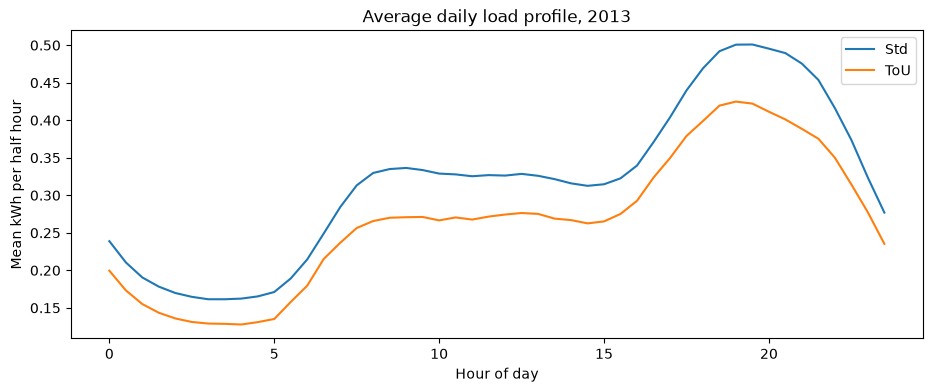

In [4]:
long = raw.melt(id_vars=["LCLid", "day"], value_vars=hh_cols, var_name="slot", value_name="kwh")
long["slot"] = long["slot"].str.replace("hh_", "").astype(int)
long = long.merge(hh[["LCLid", "stdorToU"]], on="LCLid")

profile = long.groupby(["stdorToU", "slot"])["kwh"].mean().reset_index()
profile["time"] = profile["slot"].map(lambda s: f"{s // 2:02d}:{'30' if s % 2 else '00'}")

fig, ax = plt.subplots(figsize=(11, 4))
for t, g in profile.groupby("stdorToU"):
    ax.plot(g["slot"] / 2, g["kwh"], label=t)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean kWh per half hour"); ax.legend()
ax.set_title("Average daily load profile, 2013")
plt.show()

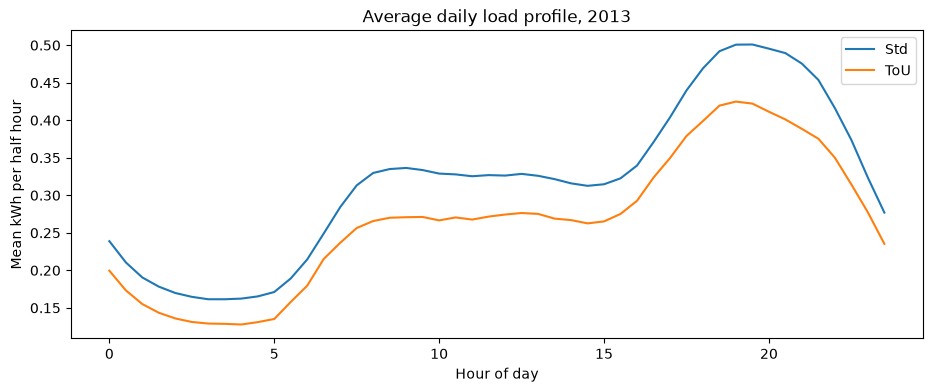

In [5]:
long = raw.melt(id_vars=["LCLid", "day"], value_vars=hh_cols, var_name="slot", value_name="kwh")
long["slot"] = long["slot"].str.replace("hh_", "").astype(int)
long = long.merge(hh[["LCLid", "stdorToU"]], on="LCLid")

profile = long.groupby(["stdorToU", "slot"])["kwh"].mean().reset_index()
profile["time"] = profile["slot"].map(lambda s: f"{s // 2:02d}:{'30' if s % 2 else '00'}")

fig, ax = plt.subplots(figsize=(11, 4))
for t, g in profile.groupby("stdorToU"):
    ax.plot(g["slot"] / 2, g["kwh"], label=t)
ax.set_xlabel("Hour of day"); ax.set_ylabel("Mean kWh per half hour"); ax.legend()
ax.set_title("Average daily load profile, 2013")
plt.show()

In [6]:
os.makedirs("../data/clean", exist_ok=True)
daily.to_parquet("../data/clean/london_household_day_2013.parquet", index=False)
profile.to_parquet("../data/clean/london_profile_by_tariff_2013.parquet", index=False)
hh_s.to_parquet("../data/clean/london_households_sample.parquet", index=False)
print("saved")

saved
